# Chapter 43: Bias and variance

Checks [chapter 43](../../book/43-bias-and-variance.md). The model is a **linear model in its weights** with two
features, fitted by ridge regression, so the floor is the ridge penalty added to the strength of every direction.
The training inputs are built so that the two directions have exact strengths 3 (signal) and 1 (noise): the feature
matrix is `Q * sqrt(strengths)` with `Q` having orthonormal columns. The new input has feature vector `(1, 1)`, and
the true weights are `(2, 0)`, so the right answer at the new input is 2, as in the chapter's example.
Everything is NumPy in float64, seeded. These are measurements, not proofs: the proofs are in `BiasVariance.lean`.
Run every cell, top to bottom. A failed check stops the notebook.

In [1]:
import sys
sys.path.append("../part1")

import numpy as np
from common import use_style, save_figure, report, NEAREST, VERTICAL, BOUND, MODEL, BEFORE
import matplotlib.pyplot as plt

use_style()
SEED = 43
NUM_POINTS = 30
SIGNAL_STRENGTH, NOISE_STRENGTH = 3.0, 1.0
NEW_INPUT = np.array([1.0, 1.0])
TRUE_WEIGHTS = np.array([2.0, 0.0])
NOISE_SCALE = 1.0
NUM_DRAWS = 40_000
FLOORS = np.linspace(0.0, 6.0, 25)


def make_design(generator):
    """Training features whose strengths (eigenvalues of features^T features) are exactly 3 and 1."""
    orthonormal, _ = np.linalg.qr(generator.standard_normal((NUM_POINTS, 2)))
    return orthonormal * np.sqrt([SIGNAL_STRENGTH, NOISE_STRENGTH]), orthonormal


def make_fitter(design, floor):
    """Ridge: weights = (features^T features + floor) ^ -1 features^T labels. Floor 0 is least squares."""
    return np.linalg.inv(design.T @ design + floor * np.eye(2)) @ design.T


def get_formula_bias(floor):
    """signal_term_sub: the right answer times minus floor / (strength + floor)."""
    return -(NEW_INPUT[0] * TRUE_WEIGHTS[0]) * floor / (SIGNAL_STRENGTH + floor)


def get_formula_variance(floor):
    """expected_sq_error: mean square of the noise overlap over (noise strength + floor) ^ 2."""
    noise_overlap_mean_square = NEW_INPUT[1] ** 2 * NOISE_STRENGTH * NOISE_SCALE ** 2
    return noise_overlap_mean_square / (NOISE_STRENGTH + floor) ** 2

## Claim 1 (by construction, cannot fail): the bias is the right answer times minus `floor / (signal_strength + floor)` (`signal_term_sub`)

Prediction: on 1000 random triples (overlap, strength, floor) with non-zero denominators, the fitted term minus the
true term equals `-(true term * floor / (strength + floor))` to rounding, about `1e-15`. The control: the wrong
fraction `floor / strength` misses by far more than `1e-3`.

This cell evaluates the chapter's formula on random numbers and compares it with the algebra the formula is built from. It is by construction, cannot fail, and is not evidence. The measured bias of Claim 3 is the real test of `signal_term_sub`.

In [2]:
generator = np.random.default_rng(SEED)
overlaps = generator.uniform(-5, 5, 1000)
strengths = generator.uniform(0.1, 5, 1000)
floors = generator.uniform(0.0, 5, 1000)
true_term = overlaps / strengths
fitted_term = overlaps / (strengths + floors)
worst_miss = np.abs((fitted_term - true_term) + true_term * floors / (strengths + floors)).max()
wrong_fraction_miss = np.abs((fitted_term - true_term) + true_term * floors / strengths).max()
report("[by construction, cannot fail] fitted minus true equals minus true times floor / (strength + floor), 1000 triples", worst_miss < 1e-12,
       f"largest miss {worst_miss:.1e}")
report("[by construction, cannot fail] the fraction floor / strength is not the bias factor", wrong_fraction_miss > 1e-3,
       f"it misses by {wrong_fraction_miss:.2f}")

[PASS] [by construction, cannot fail] fitted minus true equals minus true times floor / (strength + floor), 1000 triples  (largest miss 7.1e-15)
[PASS] [by construction, cannot fail] the fraction floor / strength is not the bias factor  (it misses by 1139.97)


True

## Claim 2: the chapter's worked example and table (from the formula, then measured in Claim 3)

Prediction, from the formulas alone: floors 0, 1, 3 give bias `0, -0.5, -1` and variance `1, 0.25, 0.0625`, so the sums
`1, 0.5, 1.0625`. These numbers are from the formula, not measured. They are printed, not checked. Claim 3 measures the same three rows by fitting.

In [3]:
table_floors = np.array([0.0, 1.0, 3.0])
table_bias = get_formula_bias(table_floors)
table_variance = get_formula_variance(table_floors)
table_sum = table_bias ** 2 + table_variance
for floor, bias, variance, total in zip(table_floors, table_bias, table_variance, table_sum):
    print(f"floor {floor:.0f}: bias {bias:+.4f}  variance {variance:.4f}  bias^2 + variance {total:.4f}")
print(f"[from the formula, not measured] table rows above; the formula's sums are {table_sum.tolist()}")


floor 0: bias -0.0000  variance 1.0000  bias^2 + variance 1.0000
floor 1: bias -0.5000  variance 0.2500  bias^2 + variance 0.5000
floor 3: bias -1.0000  variance 0.0625  bias^2 + variance 1.0625
[from the formula, not measured] table rows above; the formula's sums are [1.0, 0.5, 1.0625]


## Claim 3: the expected squared error is bias squared plus variance, measured over redrawn noise (`bias_variance`)

For each floor in a grid from 0 to 6, fit ridge regression on the same inputs with 40 000 fresh draws of Gaussian label
noise (mean 0, spread 1) laid along the noise direction, as the chapter's single noise direction, and record the error at the new input. Three numbers per floor: the mean error (the bias),
the variance of the error across draws, and the mean squared error.

Prediction: the measured bias matches `signal_term_sub`, the measured variance matches
`noise_overlap_mean_square / (noise_strength + floor) ^ 2`, and the measured mean squared error matches the sum of the
two formulas. Agreement is judged against the sampling error of each measured number: the claim fails if any point at
any of the 25 floors lies more than 4 standard errors from its formula.

The same 40 000 noise draws are reused at every floor, so the 25 distances are correlated, not independent tests: "worst of 25" is a worst case of one shared sample.

In [4]:
generator = np.random.default_rng(SEED + 1)
design, orthonormal = make_design(generator)
noise_direction = orthonormal[:, 1]            # the noise lives along the noise direction only, as in the chapter
noise_draws = generator.standard_normal((NUM_DRAWS, 1)) * NOISE_SCALE * noise_direction
true_labels = design @ TRUE_WEIGHTS
right_answer = NEW_INPUT @ TRUE_WEIGHTS

measured_bias, measured_variance, measured_mse = [], [], []
bias_error_bars, variance_error_bars, mse_error_bars = [], [], []
for floor in FLOORS:
    fitter = make_fitter(design, floor)
    weights = (fitter @ (true_labels[:, None] + noise_draws.T)).T          # one row of weights per draw
    errors = weights @ NEW_INPUT - right_answer
    squared = errors ** 2
    measured_bias.append(errors.mean())
    measured_variance.append(errors.var())
    measured_mse.append(squared.mean())
    bias_error_bars.append(errors.std() / np.sqrt(NUM_DRAWS))
    mse_error_bars.append(squared.std() / np.sqrt(NUM_DRAWS))
    variance_error_bars.append(errors.var() * np.sqrt(2.0 / (NUM_DRAWS - 1)))
measured_bias, measured_variance, measured_mse = map(np.array, (measured_bias, measured_variance, measured_mse))
bias_error_bars, variance_error_bars, mse_error_bars = map(np.array, (bias_error_bars, variance_error_bars, mse_error_bars))

formula_bias = get_formula_bias(FLOORS)
formula_variance = get_formula_variance(FLOORS)
formula_total = formula_bias ** 2 + formula_variance
sum_of_measured = measured_bias ** 2 + measured_variance

bias_z = np.abs(measured_bias - formula_bias) / bias_error_bars
variance_z = np.abs(measured_variance - formula_variance) / variance_error_bars
total_z = np.abs(measured_mse - formula_total) / mse_error_bars
print("note: the same noise draws serve all 25 floors, so these distances are correlated")
print(f"largest distance from the formula in standard errors: bias {bias_z.max():.2f}, variance {variance_z.max():.2f}, mean squared error {total_z.max():.2f}")
report("measured bias matches signal_term_sub at all 25 floors", bias_z.max() < 4, f"worst {bias_z.max():.2f} standard errors")
report("measured variance matches the formula at all 25 floors", variance_z.max() < 4, f"worst {variance_z.max():.2f} standard errors")
report("measured mean squared error matches bias^2 + variance from the formulas at all 25 floors", total_z.max() < 4,
       f"worst {total_z.max():.2f} standard errors")
for table_floor in (0.0, 1.0, 3.0):
    row = int(np.argmin(np.abs(FLOORS - table_floor)))
    print(f"measured at floor {table_floor:.0f}: bias {measured_bias[row]:+.4f}  variance {measured_variance[row]:.4f}  mean squared error {measured_mse[row]:.4f}")
table_rows = [int(np.argmin(np.abs(FLOORS - table_floor))) for table_floor in table_floors]
report("the chapter's table (floors 0, 1, 3) is reproduced by the fit: bias, variance and error within 4 standard errors",
       (np.abs(measured_bias[table_rows] - table_bias) < 4 * bias_error_bars[table_rows]).all()
       and (np.abs(measured_variance[table_rows] - table_variance) < 4 * variance_error_bars[table_rows]).all()
       and (np.abs(measured_mse[table_rows] - table_sum) < 4 * mse_error_bars[table_rows]).all())


note: the same noise draws serve all 25 floors, so these distances are correlated
largest distance from the formula in standard errors: bias 0.10, variance 1.57, mean squared error 1.58
[PASS] measured bias matches signal_term_sub at all 25 floors  (worst 0.10 standard errors)
[PASS] measured variance matches the formula at all 25 floors  (worst 1.57 standard errors)
[PASS] measured mean squared error matches bias^2 + variance from the formulas at all 25 floors  (worst 1.58 standard errors)
measured at floor 0: bias -0.0005  variance 1.0112  mean squared error 1.0112
measured at floor 1: bias -0.5003  variance 0.2528  mean squared error 0.5031
measured at floor 3: bias -1.0001  variance 0.0632  mean squared error 1.0635
[PASS] the chapter's table (floors 0, 1, 3) is reproduced by the fit: bias, variance and error within 4 standard errors


True

## Claim 4: raising the floor raises the bias and lowers the variance, and the sum is U-shaped (`bias_factor_mono`, `variance_factor_anti`)

Prediction: on the measured grid, the squared bias is non-decreasing and the variance non-increasing in the floor (a
slip of up to 4 standard errors is allowed for sampling). The measured error has its minimum strictly inside the grid,
more than 10 percent below both the floor-0 value (about 1) and the floor-6 value, and the minimiser lies within 2 grid
steps of the minimiser of the exact formulas. The chapter's own numbers: bias factor 0.25 to 0.4, and
`1 / (noise_strength + floor)` from 1/2 to 1/3, for floor 1 to 2. A flat or monotone measured error would count against
the trade-off.

In [5]:
fine_floors = np.linspace(0.0, 6.0, 6001)
formula_argmin = fine_floors[np.argmin(get_formula_bias(fine_floors) ** 2 + get_formula_variance(fine_floors))]
measured_argmin = FLOORS[np.argmin(measured_mse)]
step = FLOORS[1] - FLOORS[0]
print(f"floor that minimises the error: formula {formula_argmin:.3f}, measured on the grid {measured_argmin:.2f}")
bias_squared = measured_bias ** 2
slack_bias = 4 * 2 * (np.abs(measured_bias[1:]) * bias_error_bars[1:] + np.abs(measured_bias[:-1]) * bias_error_bars[:-1])
slack_variance = 4 * (variance_error_bars[1:] + variance_error_bars[:-1])
report("squared bias does not fall as the floor rises", (np.diff(bias_squared) > -slack_bias).all())
report("variance does not rise as the floor rises", (np.diff(measured_variance) < slack_variance).all())
report("the measured error has an interior minimum well below both ends",
       0 < np.argmin(measured_mse) < len(FLOORS) - 1 and measured_mse.min() < 0.9 * min(measured_mse[0], measured_mse[-1]),
       f"minimum {measured_mse.min():.3f}, floor 0 gives {measured_mse[0]:.3f}, floor 6 gives {measured_mse[-1]:.3f}")
report("the measured minimiser is within 2 grid steps of the formula's", abs(measured_argmin - formula_argmin) <= 2 * step,
       f"{measured_argmin:.2f} against {formula_argmin:.3f}")
bias_factors = [floor / (SIGNAL_STRENGTH + floor) for floor in (1.0, 2.0)]
variance_factors = [1.0 / (NOISE_STRENGTH + floor) for floor in (1.0, 2.0)]
report("[by construction, cannot fail] check-yourself numbers: bias factor 0.25 to 0.4, 1/(1+floor) from 1/2 to 1/3",
       np.allclose(bias_factors, [0.25, 0.4]) and np.allclose(variance_factors, [1 / 2, 1 / 3]),
       f"bias factor {bias_factors[0]:.2f} to {bias_factors[1]:.2f}, other {variance_factors[0]:.3f} to {variance_factors[1]:.3f}")

floor that minimises the error: formula 0.791, measured on the grid 0.75
[PASS] squared bias does not fall as the floor rises
[PASS] variance does not rise as the floor rises
[PASS] the measured error has an interior minimum well below both ends  (minimum 0.490, floor 0 gives 1.011, floor 6 gives 1.799)
[PASS] the measured minimiser is within 2 grid steps of the formula's  (0.75 against 0.791)
[PASS] [by construction, cannot fail] check-yourself numbers: bias factor 0.25 to 0.4, 1/(1+floor) from 1/2 to 1/3  (bias factor 0.25 to 0.40, other 0.500 to 0.333)


True

## Control: break the hypothesis `noise_part_mean_zero`

The theorem needs the noise part to be zero on average. Give the label noise a mean of 1 (every label shifted up by 1),
same spread, at floor 1. The noise part then has a mean `m` that the formulas give exactly: `m = new_input times
fitter times the noise direction`.

Prediction: the mean squared error is `(bias + m)^2 + (centred variance)`, while the chapter's right-hand side,
`bias^2 + (mean square of the noise part)`, is `bias^2 + m^2 + centred variance`. Their difference is
`2 * bias * m`, computed from the formulas, which is clearly non-zero. The check fails if the measured difference is
within 4 standard errors of zero or not within 4 standard errors of `2 * bias * m`.

Only two parts of this control can fail: the measured mean of the noise part against the formula's mean, and the measured error against the formulas' prediction `(bias + m)^2 + variance`. That the gap equals `2 * bias * (measured mean)` is algebra on the sample, by construction, cannot fail, and is not evidence.

In [6]:
control_floor = 1.0
generator = np.random.default_rng(SEED + 2)
shifted_noise = (1.0 + generator.standard_normal((NUM_DRAWS, 1)) * NOISE_SCALE) * noise_direction
fitter = make_fitter(design, control_floor)
weights = (fitter @ (true_labels[:, None] + shifted_noise.T)).T
errors = weights @ NEW_INPUT - right_answer
bias_from_signal = get_formula_bias(control_floor)
noise_part = errors - bias_from_signal
noise_part_mean_formula = NEW_INPUT @ fitter @ noise_direction
control_mse = (errors ** 2).mean()
control_rhs = bias_from_signal ** 2 + (noise_part ** 2).mean()
control_gap = control_mse - control_rhs
expected_gap = 2 * bias_from_signal * noise_part_mean_formula
gap_error_bar = 2 * abs(bias_from_signal) * noise_part.std() / np.sqrt(NUM_DRAWS)
print(f"noise part has mean {noise_part.mean():+.4f} measured, {noise_part_mean_formula:+.4f} from the formulas (the theorem needs 0)")
print(f"mean squared error {control_mse:.4f}, bias^2 + mean square of noise part {control_rhs:.4f}, difference {control_gap:+.4f}")
print(f"2 * bias * mean of noise part from the formulas = {expected_gap:+.4f}, standard error of the difference {gap_error_bar:.4f}")
noise_part_mean_error_bar = noise_part.std() / np.sqrt(NUM_DRAWS)
formula_prediction = (bias_from_signal + noise_part_mean_formula) ** 2 + get_formula_variance(control_floor)
mse_error_bar = (errors ** 2).std() / np.sqrt(NUM_DRAWS)
print(f"the formulas predict (bias + m)^2 + variance = {formula_prediction:.4f}; measured {control_mse:.4f}")
report("control: the measured mean of the noise part matches the formula's mean",
       abs(noise_part.mean() - noise_part_mean_formula) < 4 * noise_part_mean_error_bar and abs(noise_part_mean_formula) > 0.1,
       f"{noise_part.mean():+.4f} against {noise_part_mean_formula:+.4f}")
report("control: the measured error matches (bias + m)^2 + variance from the formulas",
       abs(control_mse - formula_prediction) < 4 * mse_error_bar, f"{control_mse:.4f} against {formula_prediction:.4f}")
report("[by construction, cannot fail] the gap equals 2 * bias * measured mean of the noise part",
       abs(control_gap - 2 * bias_from_signal * noise_part.mean()) < 1e-9, f"failure of size {control_gap:+.3f}")


noise part has mean +0.5014 measured, +0.5000 from the formulas (the theorem needs 0)
mean squared error 0.2495, bias^2 + mean square of noise part 0.7509, difference -0.5014
2 * bias * mean of noise part from the formulas = -0.5000, standard error of the difference 0.0025
the formulas predict (bias + m)^2 + variance = 0.2500; measured 0.2495
[PASS] control: the measured mean of the noise part matches the formula's mean  (+0.5014 against +0.5000)
[PASS] control: the measured error matches (bias + m)^2 + variance from the formulas  (0.2495 against 0.2500)
[PASS] [by construction, cannot fail] the gap equals 2 * bias * measured mean of the noise part  (failure of size -0.501)


True

## Figure

Left: the squared bias, the variance and their sum against the floor as exact formula curves, with the values measured
over 40 000 redraws of the noise as points, and the measured mean squared error on the same axes. Right: the control,
at floor 1, the measured error beside bias squared plus variance computed from the chapter's formulas (with the formula's noise-part mean, 0.5, for the shifted case), for zero-mean and for shifted noise.

wrote book/figures/43-bias-plus-variance.png


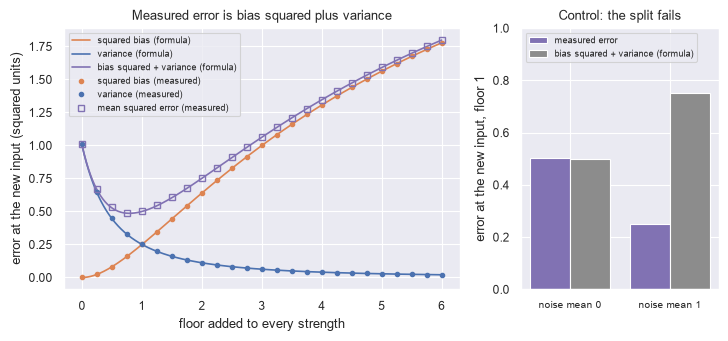

floor 1.00: measured error 0.503 against formula sum 0.500; shifted noise 0.250 against formula sum 0.750


In [7]:
figure, (left, right) = plt.subplots(1, 2, figsize=(7.4, 3.5), gridspec_kw={"width_ratios": [2.0, 1.0]})
left.plot(fine_floors, get_formula_bias(fine_floors) ** 2, color=VERTICAL, label="squared bias (formula)")
left.plot(fine_floors, get_formula_variance(fine_floors), color=NEAREST, label="variance (formula)")
left.plot(fine_floors, get_formula_bias(fine_floors) ** 2 + get_formula_variance(fine_floors), color=MODEL, label="bias squared + variance (formula)")
left.plot(FLOORS, measured_bias ** 2, "o", color=VERTICAL, markersize=3, label="squared bias (measured)")
left.plot(FLOORS, measured_variance, "o", color=NEAREST, markersize=3, label="variance (measured)")
left.plot(FLOORS, measured_mse, "s", color=MODEL, markersize=4, markerfacecolor="none", label="mean squared error (measured)")
left.set_xlabel("floor added to every strength")
left.set_ylabel("error at the new input (squared units)")
left.set_title("Measured error is bias squared plus variance")
left.legend(fontsize=6.5)
floor_one = list(FLOORS).index(1.0) if 1.0 in FLOORS else int(np.argmin(np.abs(FLOORS - 1.0)))
mse_pair = [measured_mse[floor_one], control_mse]
control_formula_sum = bias_from_signal ** 2 + noise_part_mean_formula ** 2 + get_formula_variance(control_floor)
sum_pair = [formula_total[floor_one], control_formula_sum]
positions = np.arange(2)
right.bar(positions - 0.2, mse_pair, 0.4, color=MODEL, label="measured error")
right.bar(positions + 0.2, sum_pair, 0.4, color=BEFORE, label="bias squared + variance (formula)")
right.set_xticks(positions)
right.set_xticklabels(["noise mean 0", "noise mean 1"], fontsize=7)
right.set_ylabel("error at the new input, floor 1")
right.set_title("Control: the split fails")
right.set_ylim(0, 1.0)
right.legend(fontsize=6.5, loc="upper left")
figure.tight_layout()
save_figure(figure, "43-bias-plus-variance")
plt.show()
print(f"floor {FLOORS[floor_one]:.2f}: measured error {mse_pair[0]:.3f} against formula sum {sum_pair[0]:.3f}; shifted noise {mse_pair[1]:.3f} against formula sum {sum_pair[1]:.3f}")